# 01 – Data Source Layer

**Projekt:** Wohnungsmarkt-Radar Wien – Preis/Leistungs-Score für Mietwohnungen

**Layer:** Data Source Layer - Identifikation der Datenquellen & Methoden der Datengewinnung

**Beschreibung:** Dieses Notebook beschreibt, woher die Daten kommen und wie sie gewonnen werden. Es beschreibt die Webscraper, zeigt Beispiele der Rohdaten und gibt einen Überblick über Umfang und Qualität der Daten

**Fragestellung:** 
Ist eine Mietwohnung für den Bezirk preislich günstig, normal oder teuer? Dafür bilden wir einen Preis/Leistungsscore pro Wohnung aus Gesamtmiete, Fläche, Zimmeranzahl, Lage und die Anbindung an den öffentlichen Verkehr.

**Überblick der Quellen:**

| Quelle | Art | Methode | Format | Koordinaten |
|---|---|---|---|---|
| Willhaben | Web Scraping | HTML abrufen, eingebettetes JSON (`__NEXT_DATA__`) auslesen | JSONL | ja |
| ImmoScout24 | Web Scraping | GraphQL-Schnittstelle der Website (Persisted Query) | JSONL | ja |
| DerStandard Immobilien (wird im Storage Layer nicht verwendet) | Web Scraping | HTML abrufen, Karten und eingebettetes JSON auslesen | JSONL | nein (Geocoding wäre nötig) |
| Wiener Linien: Haltestellen | Open Data | Download JSON | JSON | ja |
| Wien: Bezirksgrenzen | Open Data | Download JSON | JSON | ja (EPSG:31256) |

**Links zu den Quellen:**

•	ImmoScout24: https://www.immobilienscout24.at/portal/graphql

•	Der Standard: https://immobilien.derstandard.at/suche/wien/mieten-wohnung 

•	Willhaben: https://www.willhaben.at/iad/immobilien/mietwohnungen/mietwohnung-angebote?areaId=900

•	Öffentliches Verkehrsnetz Haltestellen Wien: https://www.data.gv.at/datasets/f1f6f15d-2faa-4b62-b78b-80599dd1c66e?locale=de

•	Bezirksgrenzen: https://www.data.gv.at/datasets/2ee6b8bf-6292-413c-bb8b-bd22dbb2ad4b?locale=de


**Willhaben-Scraper:** Der Willhaben-Scraper basiert auf dem Open-Source-Projekt willhaben von Christian Proschek (ISC-Lizenz) (https://github.com/CP02A/willhaben) - wurde aber für unsere Bedürfnisse umgebaut


**Gesamtablauf:**
```
Datasources accesed via webscraper:                 Open Data:
 Portale (Willhaben, ImmoScout24, DerStandard)      Open Data (Haltestellen, Bezirke)
              │  Node.js-Scraper (app.js)                        │  Download aus data.gv.at
              ▼                                                  ▼
        data/raw/*.jsonl                                data/external/*.geojson
              │                                                  │
              └──────────────► 02_data_storage ◄─────────────────┘





# 1. Vorbereitung

Daten holen, Pfad definieren, Dateien einlesen und Daten ausgeben

**Scraper starten und Beispieldaten fürs Notebook holen:**

In [1]:
import shutil
import subprocess
from pathlib import Path  # Falls noch nicht importiert

RUN_SCRAPER = True      # False: vorhandene Daten verwenden, nichts neu abrufen
BASE = Path.cwd().parent
SCRAPER_DIR = BASE / "immo_webscraper"

if RUN_SCRAPER:
    if shutil.which("node") is None:
        print("Node.js wurde nicht gefunden – bitte installieren oder RUN_SCRAPER = False setzen.")
    else:
        result = subprocess.run(["node", "app.js", "fast"], cwd=SCRAPER_DIR, capture_output=True,
                                text=True, encoding="utf-8", errors="replace")
        print(result.stdout[-2000:])
        if result.returncode != 0:
            print("Fehler beim Scraper:\n", result.stderr[-1500:])


[28.11.2026, 09:51:57] ▶ FAST-Lauf startet (max. 1 Seite(n) pro Quelle)
Starte Willhaben Scraping...
-> Willhaben Seite 1: 25 Anzeigen (Gesamt: 25)
Willhaben fertig: 25 Wohnungen gespeichert.

willhaben: 25 Nachrichten an Kafka (listings.raw) gesendet
Starte ImmoScout24 Scraping...
-> ImmoScout Seite 1: 20 Anzeigen (Gesamt: 20)
ImmoScout fertig: 20 Wohnungen gespeichert.

immoscout24: 20 Nachrichten an Kafka (listings.raw) gesendet
[28.11.2026, 09:52:04] ✔ FAST-Lauf beendet



**Daten einlesen:**

In [2]:
import json

def read_jsonl(filepath):
    """Liest eine JSONL-Datei zeilenweise ein und gibt eine Liste von Dicts zurück."""
    data = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                data.append(json.loads(line))
    return data

RAW = BASE / "data" / "raw"
def load_source(name, run_type=None):
    """Neueste Lauf-Datei der Quelle aus data/raw/runs/ (run_type='full' oder 'fast' zum Filtern)."""
    pattern = f"{name}_{run_type or '*'}_*.jsonl"
    runs = sorted((RAW / "runs").glob(pattern), key=lambda f: f.stem.split("_", 2)[2])
    if not runs:
        print(f"{name}: keine Lauf-Datei gefunden")
        return []
    print(f"{name}: {runs[-1].name}")
    return read_jsonl(runs[-1])

willhaben = load_source("willhaben")
immoscout = load_source("immoscout24")
standard = load_source("derstandard")
print(f"Willhaben: {len(willhaben)} | ImmoScout24: {len(immoscout)} | DerStandard: {len(standard)} Inserate")

willhaben: willhaben_fast_2026-11-28T09-51-57.jsonl
immoscout24: immoscout24_fast_2026-11-28T09-51-57.jsonl
derstandard: keine Lauf-Datei gefunden
Willhaben: 25 | ImmoScout24: 20 | DerStandard: 0 Inserate


# 2. Webscraping der Portale

Die Scraper sind in JavaScript (Node.js) geschrieben und liegen im Ordner immo_webscraper

app.js <- zentrale Steuerung der einzelnen Scraper mit node app.js
Die Scraper werden nacheinander ausgeführt:
test/willhaben_test.js      <- scrapeWillhaben()
test/immoscout24_test.js    <- scrapeImmoScout()
test/standard_test.js       <- scrapeStandard()

Jeder Scraper wird nacheinander ausgeführt und lässt 3 Sekunden Pause zwischen den Portalseiten, da sonst ein Timeout (zumindest auf Willhaben) kommt, wenn diese zu schnell gescraped werden. Die Daten werden unter data/raw als JSONL gespeichert und nicht verändert. 

**Willhaben Scraper:**
Der Scraper lädt die Suchseite, schneiden den __NEXT_DATA__ -Block aus, parst ihn und wandelt das Attribut-Array jedes Inserats (zB: {name: "PRICE", values: [...]}) in Felder wie price, estate_size ect. um. Auf Willhaben sind coordinates sowie floor vorhanden.

**ImmoScout24 Scraper:**
Die Seite lädt ihre Ergebnisse über eine GraphQL-Schnittstelle (`/portal/graphql`). Der Scraper schickt dieselbe Anfrage wie die Website (Parameter: Miete, Wohnnutzung, Region Wien, Seitengröße, Startindex) und speichert die Treffer. Koordinaten sind vorhanden (`location.lat/lon`), ein Stockwerk nicht konsistent. In der Stichprobe enthielt die Antwort teils Kauf-Inserate und Bauprojekte mit Spannen statt Einzelwerten. Diese werden erst in der Bereinigung aussortiert.

**Standard-Scraper:**
Die Suchseite liefert die Inserate als HTML-Karten und zusätzlich als eingebettetes JSON (`PropertyEntryResponse`). Der Scraper liest
- aus den Karten: Titel, Gesamtmiete, Fläche, Zimmer, Ort,
- aus dem eingebetteten JSON: Straße, PLZ, Objektart, Ausstattung (z. B. Balkon, Aufzug).

Einschränkung: DerStandard liefert keine Koordinaten. Etwa die Hälfte der Inserate hat außerdem keine Straße. Deshalb könnte die Position in der Bereinigung über Geocoding (Nominatim) oder, als grobe Näherung, über den PLZ-Mittelpunkt bestimmt werden. Da dies aber zu ungenau wäre, wird der Standard komplett aus dem Scope entfernt.

**Beispiel der Rohdaten:**
Pro Quelle ein Inserat und nur die wichtigsten Felder:


In [3]:
def show(rows, fields, title):
    print(f"--- {title} ---")
    if not rows:
        print("(keine Daten)\n"); return
    r = rows[0]
    print(json.dumps({k: r.get(k) for k in fields}, ensure_ascii=False, indent=2), "\n")

show(willhaben, ["id", "heading", "location", "postcode", "price", "estate_size", "number_of_rooms", "floor", "coordinates"], "Willhaben")
show(immoscout, ["exposeId", "headline", "addressString", "primaryPrice", "primaryArea", "numberOfRooms", "location"], "ImmoScout24")
show(standard, ["id", "title", "location", "plz", "street", "price", "area_m2", "rooms", "property_type"], "DerStandard")

--- Willhaben ---
{
  "id": "854794716",
  "heading": "Voll ausgestattete Single Wohnung",
  "location": "Wien, 16. Bezirk, Ottakring",
  "postcode": 1160,
  "price": 650,
  "estate_size": 12,
  "number_of_rooms": 1,
  "floor": 0,
  "coordinates": "48.20914,16.32771"
} 

--- ImmoScout24 ---
{
  "exposeId": "68ef90538c4b5843c5d4b14c",
  "headline": "EDMUND - Wohnen in Strebersdorf",
  "addressString": "Edmund Hawranek Platz 1, 1210 Wien",
  "primaryPrice": 495000,
  "primaryArea": 77.51,
  "numberOfRooms": 3,
  "location": {
    "type": "POINT",
    "lat": 48.29177,
    "lon": 16.38727,
    "__typename": "PointLocation"
  }
} 

--- DerStandard ---
(keine Daten)



# 3. Umfang und Vollständigkeit der Rohdaten

Wieviele Inserate liefert jede Quelle und vorab Analyse der Daten die wir für unseren Score und unser ML-Model brauchen

In [4]:
import pandas as pd

FIELDS = {
    "willhaben":   {"Preis": "price",        "Fläche": "estate_size",  "Zimmer": "number_of_rooms", "Koordinaten": "coordinates", "Stockwerk": "floor", "Freifläche (Flag)": "has_outdoor_space", "Privat (Flag)": "is_private", "Gewerblich (Flag)": "is_commercial"},
    "immoscout24": {"Preis": "primaryPrice", "Fläche": "primaryArea",  "Zimmer": "numberOfRooms",   "Koordinaten": "location",    "Stockwerk": None, "Freifläche (Flag)": "has_outdoor_space", "Privat (Flag)": "is_private", "Gewerblich (Flag)": "is_commercial"},
    "derstandard": {"Preis": "price",        "Fläche": "area_m2",      "Zimmer": "rooms",           "Koordinaten": None,          "Stockwerk": None, "Freifläche (Flag)": "has_outdoor_space", "Privat (Flag)": "is_private", "Gewerblich (Flag)": "is_commercial"},
}

#Flags erstellen
# Für Willhaben
for rows in willhaben:
    # Miete vs. Kauf
    seo_url = str(rows.get("seo_url", "")).lower()
    
    # Preis sicher in eine Zahl umwandeln
    raw_price = rows.get("price", 0)
    try:
        price_val = float(raw_price) if raw_price is not None else 0
    except (ValueError, TypeError):
        price_val = 0

    has_rent_key = "rent/per_month_lettings" in rows or (0 < price_val < 50000)
    is_rent = 1 if ("/mietwohnungen/" in seo_url or has_rent_key) else 0
    rows["is_rent"] = is_rent
    rows["is_buy"] = 1 - is_rent
    rows["has_outdoor_space"] = 1 if (rows.get("free_area_type_name") or (rows.get("free_area/free_area_area_total") or 0) > 0) else 0
    rows["is_private"] = 1 if rows.get("isprivate") in (1, True, "1") else 0
    rows["is_commercial"] = 1 - rows["is_private"]

# Für ImmoScout24
for row in immoscout:
    # Miete vs. Kauf
    meta = row.get("meta", {})
    transfer_type = meta.get("transferType", "") if isinstance(meta, dict) else ""
    
    # Preis sicher in float umwandeln
    raw_price = row.get("primaryPrice", 0)
    try:
        price_val = float(raw_price) if raw_price is not None else 0
    except (ValueError, TypeError):
        price_val = 0

    is_rent = 1 if (transfer_type == "RENT" or 0 < price_val < 50000) else 0
    row["is_rent"] = is_rent
    row["is_buy"] = 1 - is_rent

    # Freifläche (outdoor space)
    has_outdoor = 0
    badges = row.get("typedBadges", [])
    if isinstance(badges, list):
        for b in badges:
            details = b.get("details", {}) if isinstance(b, dict) else {}
            val = str(details.get("value", "")).upper()
            if any(kw in val for kw in ["BALCONY", "TERRACE", "GARDEN", "LOGGIA"]):
                has_outdoor = 1
                break
    if not has_outdoor and any(kw in str(row).upper() for kw in ["BALCONY", "BALKON", "TERRACE", "TERRASSE"]):
        has_outdoor = 1
    row["has_outdoor_space"] = has_outdoor

    # Anbieter Status
    is_priv = row.get("isPrivate") is True
    row["is_private"] = 1 if is_priv else 0
    row["is_commercial"] = 0 if is_priv else 1


# Für Der Standard
for row in standard:
    # Miete vs. Kauf
    title = str(row.get("title", "")).lower()
    
    # Preis sicher in float umwandeln
    raw_price = row.get("price", 0)
    try:
        price_val = float(raw_price) if raw_price is not None else 0
    except (ValueError, TypeError):
        price_val = 0

    is_rent = 1 if ("miet" in title or "unbefristet" in title or 0 < price_val < 50000) else 0
    row["is_rent"] = is_rent
    row["is_buy"] = 1 - is_rent

    # Freifläche (outdoor space) aus 'amenities'
    amenities = row.get("amenities", [])
    has_outdoor = 0
    if isinstance(amenities, list):
        if any(item in amenities for item in ["BALCONY", "TERRACE", "GARDEN", "LOGGIA"]):
            has_outdoor = 1
    row["has_outdoor_space"] = has_outdoor

    # Anbieter Status
    is_priv = row.get("isPrivate") is True
    row["is_private"] = 1 if is_priv else 0
    row["is_commercial"] = 0 if is_priv else 1

DATA = {"willhaben": willhaben, "immoscout24": immoscout, "derstandard": standard}


def share(rows, field):
    """Anteil der Inserate (in %), bei denen das Feld einen Wert hat bzw true ist."""
    if not rows or field is None:
        return 0.0
    filled = sum(1 for r in rows if r.get(field) not in (None, "", [], False, 0))
    return round(100 * filled / len(rows), 1)


overview = pd.DataFrame({
    name: {"Anzahl Inserate": len(rows),
           "Anzahl verschiedener Felder": len({k for r in rows for k in r}),
           "Anzahl Miete": sum(1 for r in rows if r.get("is_rent") == 1),
           "Anzahl Kauf": sum(1 for r in rows if r.get("is_buy") == 1),
           **{f"{label} vorhanden (%)": share(rows, field) for label, field in FIELDS[name].items()}}
    for name, rows in DATA.items()
})
overview

,willhaben,immoscout24,derstandard
Anzahl Inserate,25.0,20.0,0.0
Anzahl verschiedener Felder,67.0,40.0,0.0
Anzahl Miete,25.0,18.0,0.0
Anzahl Kauf,0.0,2.0,0.0
Preis vorhanden (%),100.0,85.0,0.0
Fläche vorhanden (%),100.0,85.0,0.0
Zimmer vorhanden (%),100.0,85.0,0.0
Koordinaten vorhanden (%),100.0,100.0,0.0
Stockwerk vorhanden (%),60.0,0.0,0.0
Freifläche (Flag) vorhanden (%),80.0,70.0,0.0


# 4. Open Data

**Haltestellen der Wiener Linien:**
JSON mit allen Haltestellen als Punkte (Längen- und Breitengrad). Wichtige Felder sind: HTXT (Name), HLINIEN(Linien wie 12,5,ect.), LTYP(Linientyp)
Laut data.gv.at ist die Aufschlüsselung der Linientypen folgende:

1 = Straßenbahn
2 = Autobus (städtisch)
3 = Regionalbus
4 = U-Bahn
5 = S- und Regionalbahn
6 = Badner Bahn

**Bezirksgrenzen:**
JSON mit den 23 Wiener Bezirken, die Koordinaten liegen nicht in Längen- und Breitengraden vor, sondern im Gauß-Krüger-System EPSG:31256 und werden bei der Verarbeitung umgerechnet.

**Einlesen der Haltestellen und Mapping auf die Linientypen:**

In [5]:
EXTERNAL = BASE / "data" / "external"
stops_file = EXTERNAL / "haltestellen.json"
if stops_file.exists():
    stops = json.loads(stops_file.read_text(encoding="utf-8"))["features"]
    props = pd.DataFrame([f["properties"] for f in stops])
    
    # Mapping für den Wiener Linientyp (LTYP)
    lt_mapping = {
        1: "Straßenbahn",
        2: "Autobus",
        3: "Regionalbus",
        4: "U-Bahn",
        5: "S-Bahn / Regionalbahn",
        6: "Badner Bahn",
        9: "Sonstige / AST",
        10: "Nachtbus",
        11: "Nachtbus",
        12: "Sonderform",
        13: "Sonderform"
    }
    
    # Neue lesbare Spalte hinzufügen (unbekannte Typen fangen wir mit .get ab)
    props["LTYP_Text"] = props["LTYP"].map(lt_mapping).fillna("Unbekannt")
    
    print(f"Haltestellen: {len(stops)} Punkte")
    print("\nVerteilung nach Linientyp:")
    # Wir zeigen gleich die praktische Text-Verteilung statt nur der reinen Zahlen
    print(props["LTYP_Text"].value_counts().to_string())
    
    print("\nBeispiel:")
    print(props[["HTXT", "HLINIEN", "LTYP", "LTYP_Text"]].head(3).to_string(index=False))
else:
    print(f"{stops_file} nicht gefunden")

Haltestellen: 10461 Punkte

Verteilung nach Linientyp:
LTYP_Text
Autobus                  3580
Regionalbus              2459
Nachtbus                 2448
Straßenbahn               957
Sonderform                734
S-Bahn / Regionalbahn     140
U-Bahn                     99
Sonstige / AST             44

Beispiel:
                                            HTXT      HLINIEN  LTYP   LTYP_Text
Friedrich-Engels-Platz (Adalbert-Stifter-Straße) N29, N31, N8    11    Nachtbus
                          Friedrich-Engels-Platz   12,30,31,5     1 Straßenbahn
        Friedrich-Engels-Platz (Vorgartenstraße)       11A,5A     2     Autobus


**Einlesen und umrechnen der Bezirksgrenzen:**

In [6]:
bezirke_file = EXTERNAL / "bezirksgrenzen.json"
if bezirke_file.exists():
    bezirke = json.loads(bezirke_file.read_text(encoding="utf-8"))["features"]
    print(f"Bezirksgrenzen: {len(bezirke)} Polygone")
    coords = bezirke[0]["geometry"]["coordinates"]
    while isinstance(coords[0], list):
        coords = coords[0]
    x, y = coords[0], coords[1]
    print(f"Erste Koordinate in der Datei: x={x}, y={y}  -> kein Längen-/Breitengrad (EPSG:31256)")
    try:
        from pyproj import Transformer
        lon, lat = Transformer.from_crs("EPSG:31256", "EPSG:4326", always_xy=True).transform(x, y)
        print(f"Umgerechnet nach WGS84: Breite {lat:.4f}, Länge {lon:.4f}  ->  liegt in Wien")
    except ImportError:
        print("(pyproj nicht installiert: pip install pyproj)")
else:
    print(f"{bezirke_file} nicht gefunden")

Bezirksgrenzen: 23 Polygone
Erste Koordinate in der Datei: x=2803.3126, y=340241.844  -> kein Längen-/Breitengrad (EPSG:31256)
Umgerechnet nach WGS84: Breite 48.2006, Länge 16.3698  ->  liegt in Wien


**Bezirksgrenzen visualisieren:**

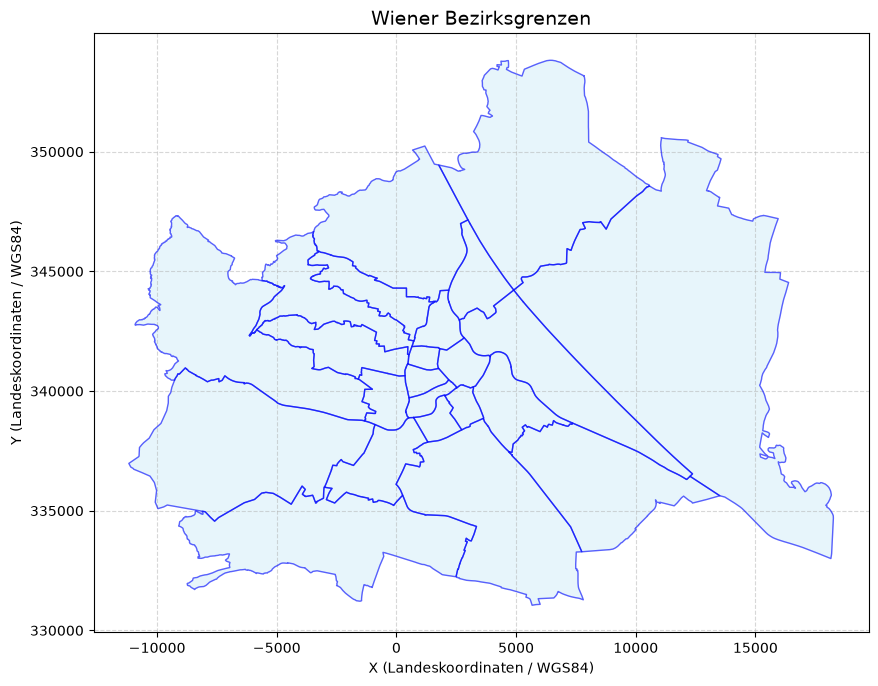

In [7]:
import json
import matplotlib.pyplot as plt
from pathlib import Path  # Falls noch nicht importiert

bezirke_file = EXTERNAL / "bezirksgrenzen.json"

if bezirke_file.exists():
    bezirke = json.loads(bezirke_file.read_text(encoding="utf-8"))["features"]
    
    fig, ax = plt.subplots(figsize=(10, 10))
    
    # Durchlaufe alle Bezirke
    for b in bezirke:
        geometry = b["geometry"]
        geom_type = geometry["type"]
        coords = geometry["coordinates"]
        name = b["properties"].get(
            "NAME", "Bezirk"
        )  # Bezirksname (je nach JSON-Struktur)

        if geom_type == "Polygon":
            # Ein einfaches Polygon (äußere Ringe)
            for ring in coords:
                x = [p[0] for p in ring]
                y = [p[1] for p in ring]
                ax.plot(x, y, color="blue", alpha=0.6, linewidth=1)
                ax.fill(x, y, color="skyblue", alpha=0.2)

        elif geom_type == "MultiPolygon":
            # MultiPolygon
            for polygon in coords:
                for ring in polygon:
                    x = [p[0] for p in ring]
                    y = [p[1] for p in ring]
                    ax.plot(x, y, color="blue", alpha=0.6, linewidth=1)
                    ax.fill(x, y, color="skyblue", alpha=0.2)

    ax.set_title("Wiener Bezirksgrenzen", fontsize=14)
    ax.set_xlabel("X (Landeskoordinaten / WGS84)")
    ax.set_ylabel("Y (Landeskoordinaten / WGS84)")
    ax.set_aspect("equal")  # Verhindert, dass die Karte verzerrt wird
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()
else:
    print(f"{bezirke_file} nicht gefunden")

**Bezirksgrenzen und Haltestellen visualisieren:**

-Note: Da die Haltestellen die gesamte VOR-Region abdecken, werden Haltestellen außerhalb der Wiener Stadtgrenze entfernt

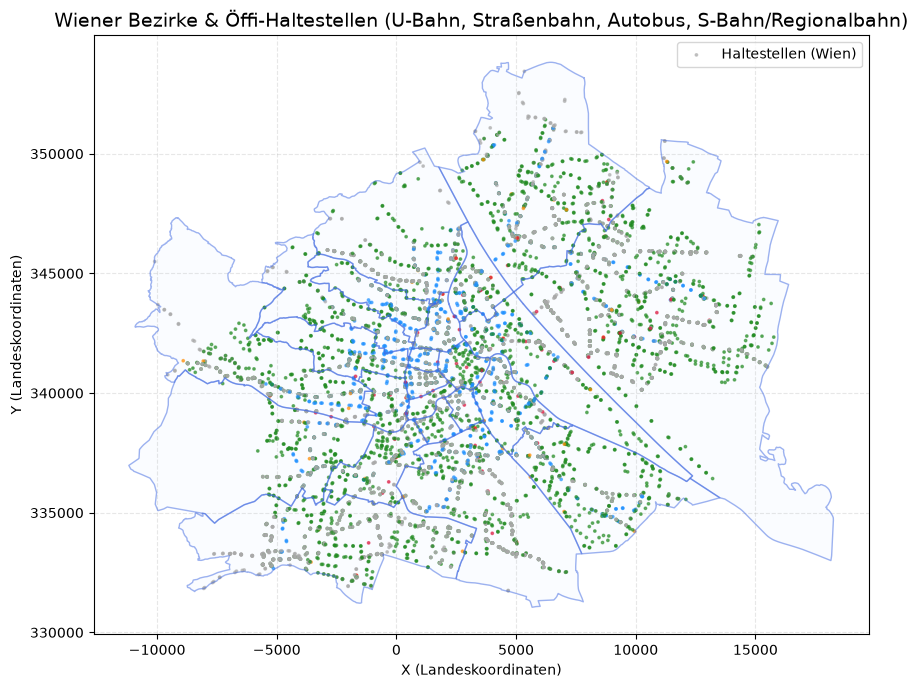

In [8]:
import json
import matplotlib.pyplot as plt
from pathlib import Path
from pyproj import Transformer
from shapely.geometry import shape, Point
from shapely.ops import unary_union


bezirke_file = EXTERNAL / "bezirksgrenzen.json"
stops_file = EXTERNAL / "haltestellen.json"

fig, ax = plt.subplots(figsize=(10, 10))

# 1. LAYER: Bezirksgrenzen laden und zu einer Stadtgrenze vereinen
vienna_poly = None
if bezirke_file.exists():
    bezirke = json.loads(bezirke_file.read_text(encoding="utf-8"))["features"]
    
    # Alle Bezirke zu einem großen Polygon-Objekt verschmelzen
    polys = [shape(b["geometry"]) for b in bezirke]
    vienna_poly = unary_union(polys)
    
    # Bezirke einzeichnen
    for b in bezirke:
        geometry = b["geometry"]
        geom_type = geometry["type"]
        coords = geometry["coordinates"]

        if geom_type == "Polygon":
            for ring in coords:
                x = [p[0] for p in ring]
                y = [p[1] for p in ring]
                ax.plot(x, y, color="#4169E1", alpha=0.5, linewidth=1)
                ax.fill(x, y, color="#F0F8FF", alpha=0.3)
        elif geom_type == "MultiPolygon":
            for polygon in coords:
                for ring in polygon:
                    x = [p[0] for p in ring]
                    y = [p[1] for p in ring]
                    ax.plot(x, y, color="#4169E1", alpha=0.5, linewidth=1)
                    ax.fill(x, y, color="#F0F8FF", alpha=0.3)

# 2. LAYER: Haltestellen transformieren und auf Wien filtern
if stops_file.exists() and vienna_poly is not None:
    stops = json.loads(stops_file.read_text(encoding="utf-8"))["features"]
    
    transformer = Transformer.from_crs("EPSG:4326", "EPSG:31256", always_xy=True)
    
    stop_x, stop_y, stop_colors = [], [], []
    
    color_map = {
        4: "#DC143C", # U-Bahn
        1: "#1E90FF", # Straßenbahn
        2: "#228B22", # Autobus
        5: "#FF8C00",  # S-Bahn
        6: "#8A2BE2"  # Badner Bahn
    }
    
    for f in stops:
        props = f["properties"]
        geom = f["geometry"]
        if geom and geom["type"] == "Point":
            lon, lat = geom["coordinates"]
            x_proj, y_proj = transformer.transform(lon, lat)
            point = Point(x_proj, y_proj)
            
            # ✨ Nur behalten, wenn der Punkt innerhalb von Wien liegt!
            if vienna_poly.contains(point):
                lt = props.get("LTYP")
                stop_x.append(x_proj)
                stop_y.append(y_proj)
                stop_colors.append(color_map.get(lt, "#A9A9A9"))

    ax.scatter(stop_x, stop_y, c=stop_colors, s=3, alpha=0.6, label="Haltestellen (Wien)")

ax.set_title("Wiener Bezirke & Öffi-Haltestellen (U-Bahn, Straßenbahn, Autobus, S-Bahn/Regionalbahn)", fontsize=14)
ax.set_xlabel("X (Landeskoordinaten)")
ax.set_ylabel("Y (Landeskoordinaten)")
ax.set_aspect("equal")
ax.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.3)
plt.show()

**Ergänzen der Willhaben und ImmoScout24 anzeigen:**

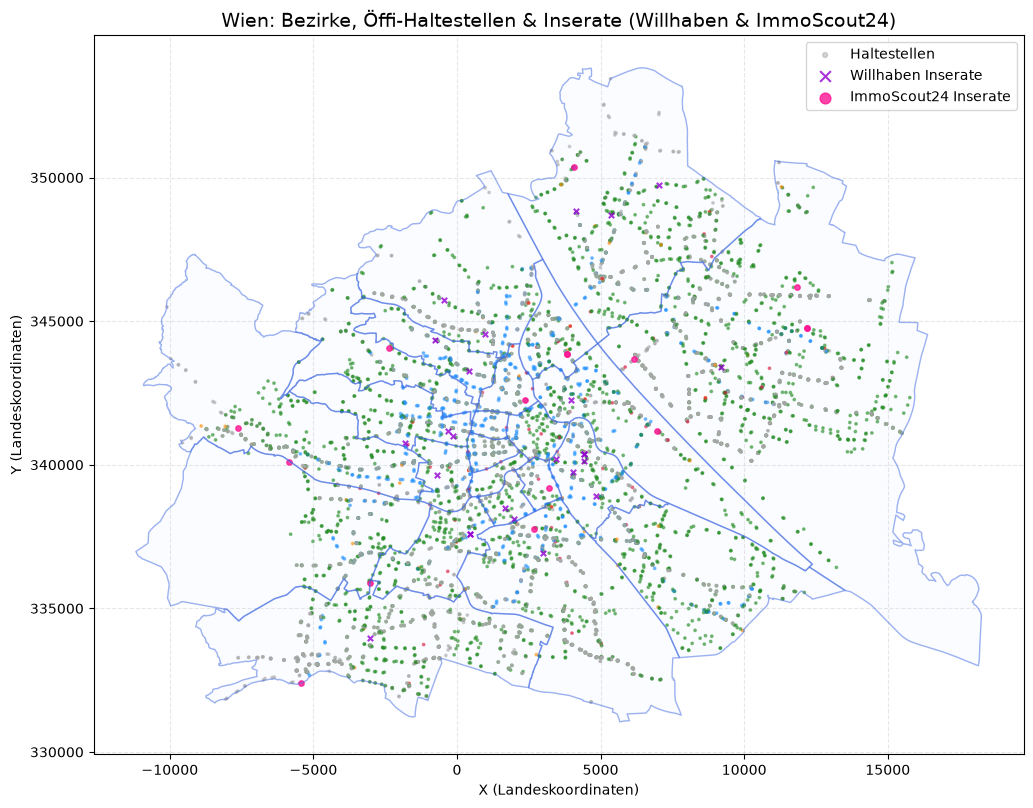

In [9]:
import json
import matplotlib.pyplot as plt
from pathlib import Path
from pyproj import Transformer
from shapely.geometry import shape, Point
from shapely.ops import unary_union

bezirke_file = EXTERNAL / "bezirksgrenzen.json"
stops_file = EXTERNAL / "haltestellen.json"

fig, ax = plt.subplots(figsize=(12, 12))

# Transformer für Koordinaten (WGS84 -> Wiener Landeskoordinaten EPSG:31256)
transformer = Transformer.from_crs("EPSG:4326", "EPSG:31256", always_xy=True)

# 1. LAYER: Bezirksgrenzen laden und zu einer Stadtgrenze vereinen
vienna_poly = None
if bezirke_file.exists():
    bezirke = json.loads(bezirke_file.read_text(encoding="utf-8"))["features"]
    
    polys = [shape(b["geometry"]) for b in bezirke]
    vienna_poly = unary_union(polys)
    
    for b in bezirke:
        geometry = b["geometry"]
        geom_type = geometry["type"]
        coords = geometry["coordinates"]

        if geom_type == "Polygon":
            for ring in coords:
                x = [p[0] for p in ring]
                y = [p[1] for p in ring]
                ax.plot(x, y, color="#4169E1", alpha=0.5, linewidth=1)
                ax.fill(x, y, color="#F0F8FF", alpha=0.3)
        elif geom_type == "MultiPolygon":
            for polygon in coords:
                for ring in polygon:
                    x = [p[0] for p in ring]
                    y = [p[1] for p in ring]
                    ax.plot(x, y, color="#4169E1", alpha=0.5, linewidth=1)
                    ax.fill(x, y, color="#F0F8FF", alpha=0.3)

# 2. LAYER: Haltestellen transformieren und auf Wien filtern
if stops_file.exists() and vienna_poly is not None:
    stops = json.loads(stops_file.read_text(encoding="utf-8"))["features"]
    
    stop_x, stop_y, stop_colors = [], [], []
    color_map = {
        4: "#DC143C", # U-Bahn
        1: "#1E90FF", # Straßenbahn
        2: "#228B22", # Autobus
        5: "#FF8C00", # S-Bahn
        6: "#8A2BE2"  # Badner Bahn
    }
    
    for f in stops:
        props = f["properties"]
        geom = f["geometry"]
        if geom and geom["type"] == "Point":
            lon, lat = geom["coordinates"]
            x_proj, y_proj = transformer.transform(lon, lat)
            point = Point(x_proj, y_proj)
            
            if vienna_poly.contains(point):
                lt = props.get("LTYP")
                stop_x.append(x_proj)
                stop_y.append(y_proj)
                stop_colors.append(color_map.get(lt, "#A9A9A9"))

    ax.scatter(stop_x, stop_y, c=stop_colors, s=3, alpha=0.5, label="Haltestellen")

# 3. LAYER: Inserate (Willhaben & ImmoScout24) einzeichnen
if vienna_poly is not None:
    # A) Willhaben Inserate (Koordinatenformat: "lat,lon" als String)
    if 'willhaben' in locals() and willhaben:
        wh_x, wh_y = [], []
        for r in willhaben:
            coords_str = r.get("coordinates")
            if coords_str and isinstance(coords_str, str) and "," in coords_str:
                try:
                    lat_s, lon_s = map(float, coords_str.split(","))
                    x_p, y_p = transformer.transform(lon_s, lat_s)
                    pt = Point(x_p, y_p)
                    if vienna_poly.contains(pt):
                        wh_x.append(x_p)
                        wh_y.append(y_p)
                except ValueError:
                    continue
        ax.scatter(wh_x, wh_y, c="#9400D3", s=15, marker="x", alpha=0.8, label="Willhaben Inserate")

    # B) ImmoScout24 Inserate (Koordinatenformat: Dictionary mit {"lat": ..., "lon": ...})
    if 'immoscout' in locals() and immoscout:
        im_x, im_y = [], []
        for r in immoscout:
            loc = r.get("location")
            if loc and isinstance(loc, dict) and "lat" in loc and "lon" in loc:
                try:
                    lat_s = float(loc["lat"])
                    lon_s = float(loc["lon"])
                    x_p, y_p = transformer.transform(lon_s, lat_s)
                    pt = Point(x_p, y_p)
                    if vienna_poly.contains(pt):
                        im_x.append(x_p)
                        im_y.append(y_p)
                except (ValueError, TypeError):
                    continue
        ax.scatter(im_x, im_y, c="#FF1493", s=15, marker="o", alpha=0.8, label="ImmoScout24 Inserate")

ax.set_title("Wien: Bezirke, Öffi-Haltestellen & Inserate (Willhaben & ImmoScout24)", fontsize=14)
ax.set_xlabel("X (Landeskoordinaten)")
ax.set_ylabel("Y (Landeskoordinaten)")
ax.set_aspect("equal")
ax.legend(loc="upper right", markerscale=2)
plt.grid(True, linestyle="--", alpha=0.3)
plt.show()

# 5. Zeitsteuerung - Batch-Betrieb

Die Daten werden im laufenden Betrieb nicht nur einmal geholt sondern laufend aktualsisiert. app.js steuert das zeitlich:

node app.js full -> einmaliger vollständiger Lauf (alle Seiten jeder Quelle werden geladen 

-> im Dauerbetrieb täglich zwischen 03:00 und 06:00)

node app.js fast -> einmaliger schneller Lauf (nur die erste Seite jeder Quelle wird geladen  

-> im Dauerbetrieb alle 10 Minuten)

node app.js -> Scheduler (der Dauerbetrieb)

Notes:

-> Zufällige Startzeit im Fenster bei vollständigem Lauf

-> Nie zwei Läufe gleichzeitig (bei schnellen Läufen)

-> Fällt eine Quelle aus, laufen die anderen Weiter

Ausgabe:

-> Jeder Lauf schreibt pro Quelle eine eigene Datei in data/raw/runs mit Zeitstempel

-> Jede Zeile in den Daten erhält zusätzlich _scraped_at und _run_type (fast oder full)

-> Ein voller Lauf aktualisiert den Gesamtstand

# 6. Kafka-Producer

Nach jedem Lauf schickt app.js die Inserate als Nachricht an das Kafka-Topic listings.raw (Key: quelle:id, Value: das JSON, inkl. _scraped_at & _run_type). Die Laufdateien bleiben als Backup bestehen.